# 10 — LightGBM

**Algorithm:** LightGBM (Light Gradient Boosting Machine)  
**Features:** TF-IDF (50K unigrams + bigrams, sparse)  
LightGBM uses leaf-wise tree growth and histogram-based splitting, making it significantly faster than traditional GBM while often achieving higher accuracy.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, evaluate_and_print, plot_confusion_matrix,
                   plot_roc_curve, plot_pr_curve, plot_learning_curve)
from sklearn.metrics import accuracy_score, log_loss
BASE_DIR, FIGURES_DIR = setup_paths()

try:
    import lightgbm as lgb
    print(f'LightGBM version: {lgb.__version__}')
except ImportError:
    raise ImportError('LightGBM is not installed. Run: pip install lightgbm')

LightGBM version: 4.6.0


In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2), sublinear_tf=True, min_df=2, max_df=0.95)
X_tr = tfidf.fit_transform(X_train)
X_te = tfidf.transform(X_test)
print(f'Train: {len(X_train):,}  |  Test: {len(X_test):,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
Train: 83,616  |  Test: 20,905


## Model Training with Eval Log

In [3]:
from lightgbm import LGBMClassifier
MODEL_NAME = 'LightGBM'
eval_results = {}
callbacks = [lgb.record_evaluation(eval_results), lgb.early_stopping(10, verbose=False)]
model = LGBMClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbose=-1)
t0 = time.time()
model.fit(X_tr, y_train,
          eval_set=[(X_tr, y_train), (X_te, y_test)],
          eval_names=['train', 'test'],
          eval_metric='binary_logloss',
          callbacks=callbacks)
train_time = time.time() - t0
print(f'Training completed in {train_time:.2f}s')
print(f'Best iteration: {model.best_iteration_}')

Training completed in 93.81s
Best iteration: 100


In [4]:
metrics, y_pred, y_prob = evaluate_and_print(model, X_te, y_test, MODEL_NAME, train_time)


  LightGBM — Evaluation Results
  Accuracy          : 0.8532
  Precision         : 0.8576
  Recall            : 0.8532
  F1 Score          : 0.8501
  AUC-ROC           : 0.9382
  Train Time (s)    : 93.81s

              precision    recall  f1-score   support

    Fake (0)       0.89      0.73      0.80      8532
    Real (1)       0.83      0.94      0.88     12373

    accuracy                           0.85     20905
   macro avg       0.86      0.83      0.84     20905
weighted avg       0.86      0.85      0.85     20905



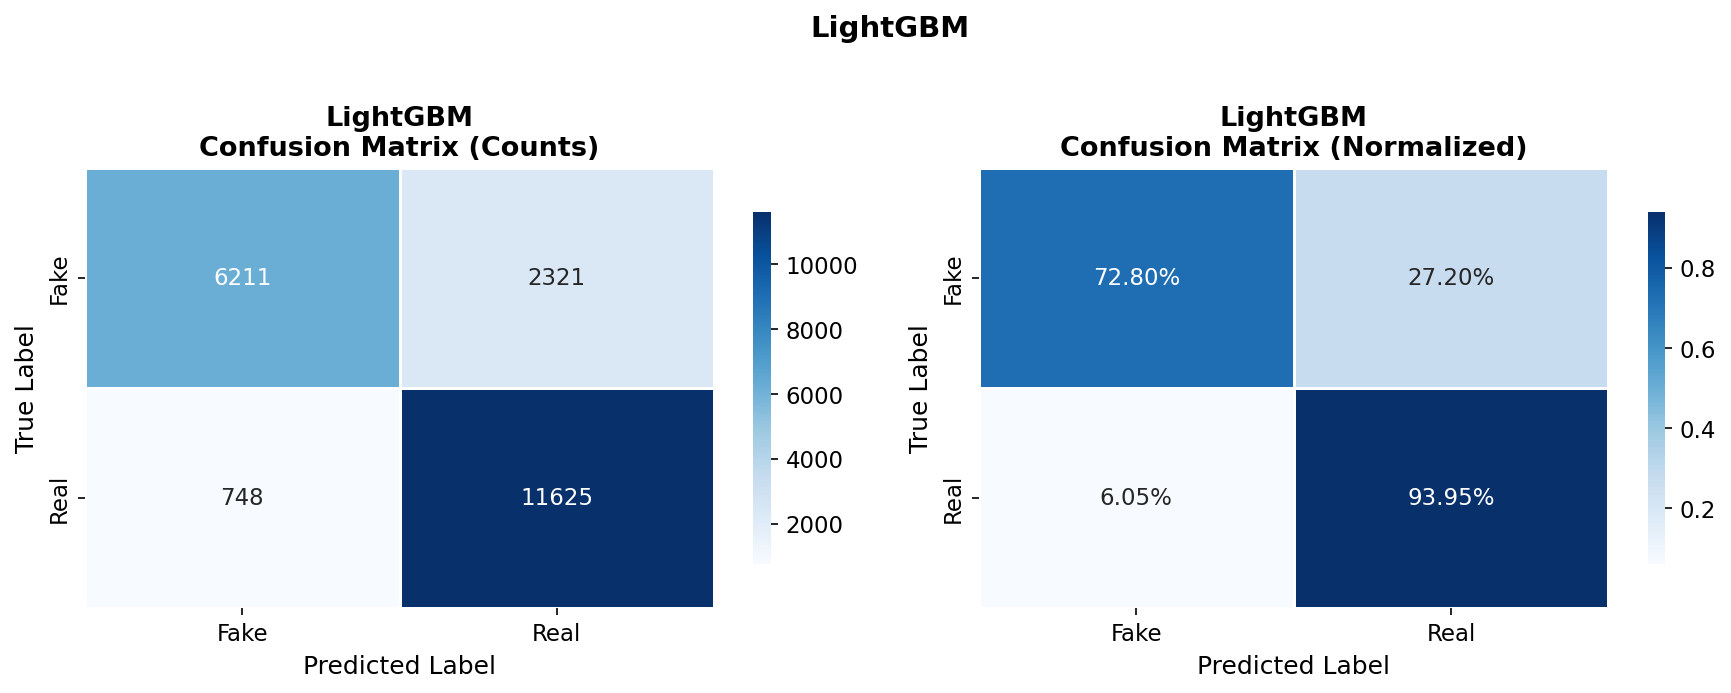

In [5]:
plot_confusion_matrix(y_test, y_pred, MODEL_NAME, FIGURES_DIR)

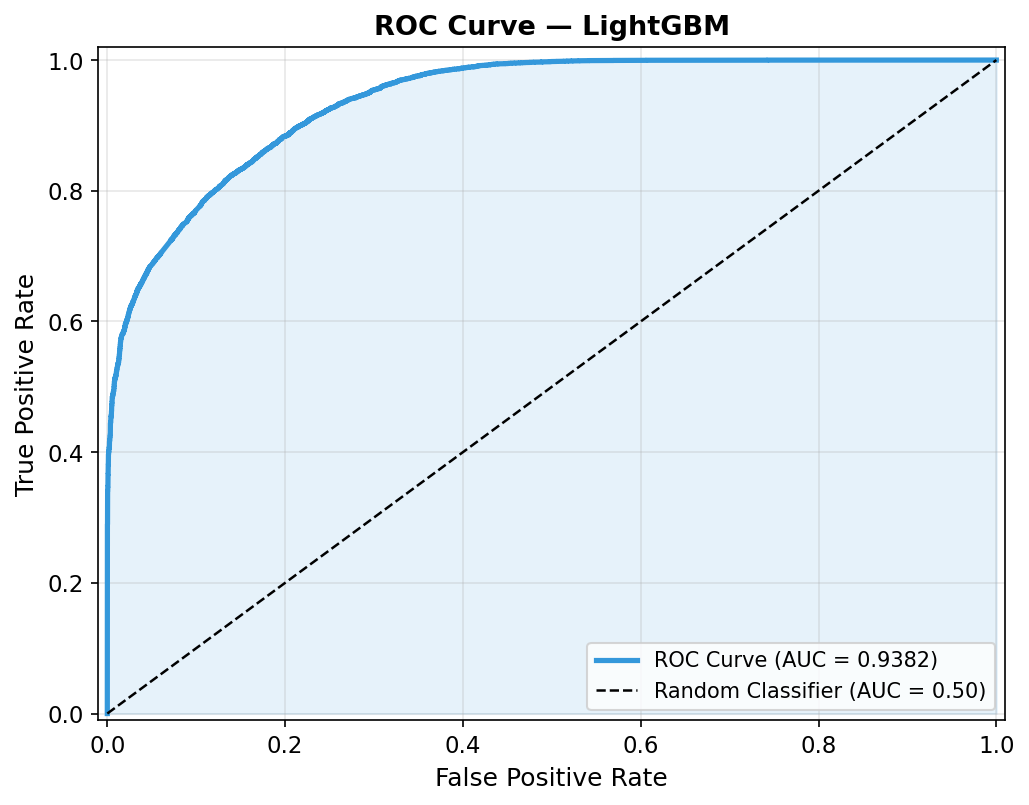

In [6]:
plot_roc_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

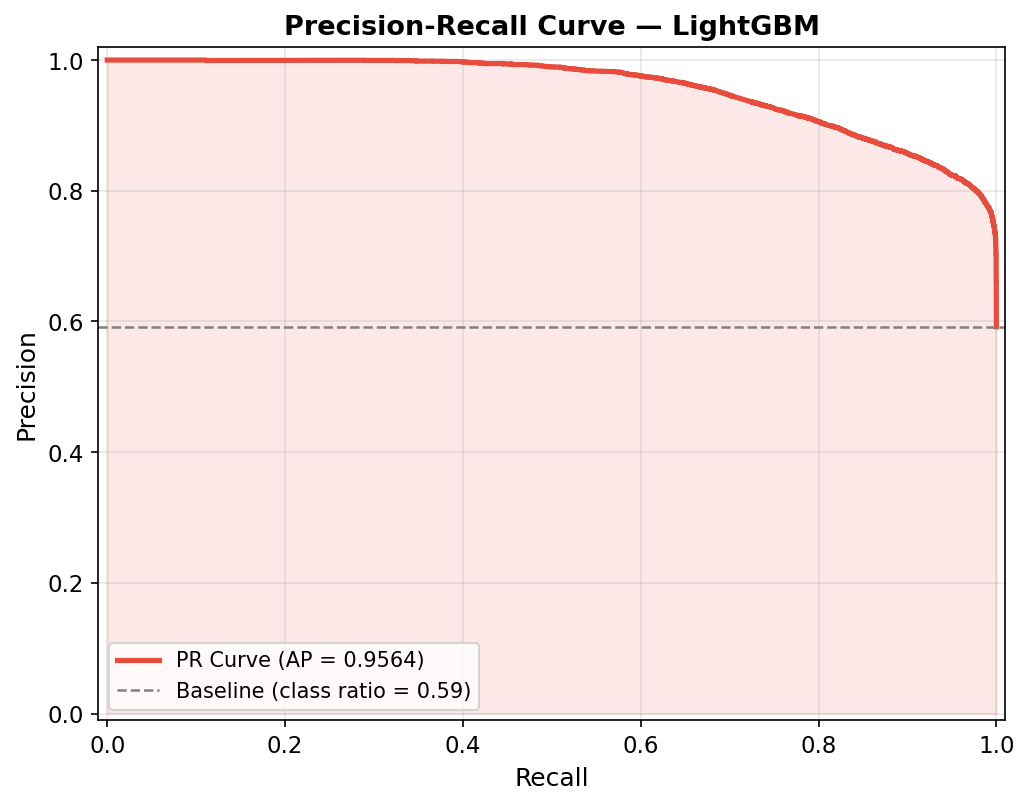

In [7]:
plot_pr_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

## Training Convergence: Log-Loss per Round

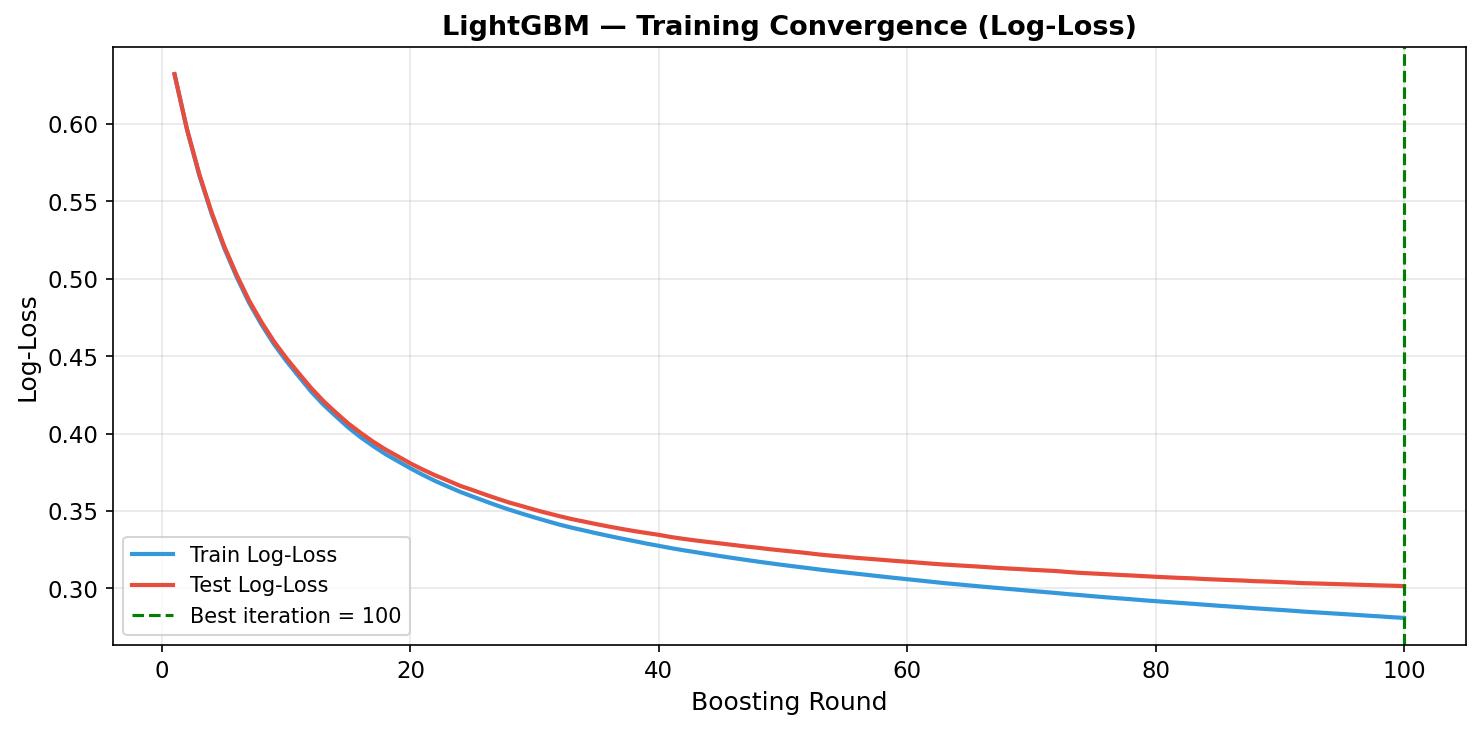

In [8]:
tr_loss = eval_results['train']['binary_logloss']
te_loss = eval_results['test']['binary_logloss']
iterations = np.arange(1, len(tr_loss) + 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(iterations, tr_loss, color='#3498db', lw=2, label='Train Log-Loss')
ax.plot(iterations, te_loss, color='#e74c3c', lw=2, label='Test Log-Loss')
if model.best_iteration_:
    ax.axvline(model.best_iteration_, color='green', linestyle='--', lw=1.5,
               label=f'Best iteration = {model.best_iteration_}')
ax.set_xlabel('Boosting Round')
ax.set_ylabel('Log-Loss')
ax.set_title('LightGBM — Training Convergence (Log-Loss)')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'lightgbm_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()

## Feature Importances

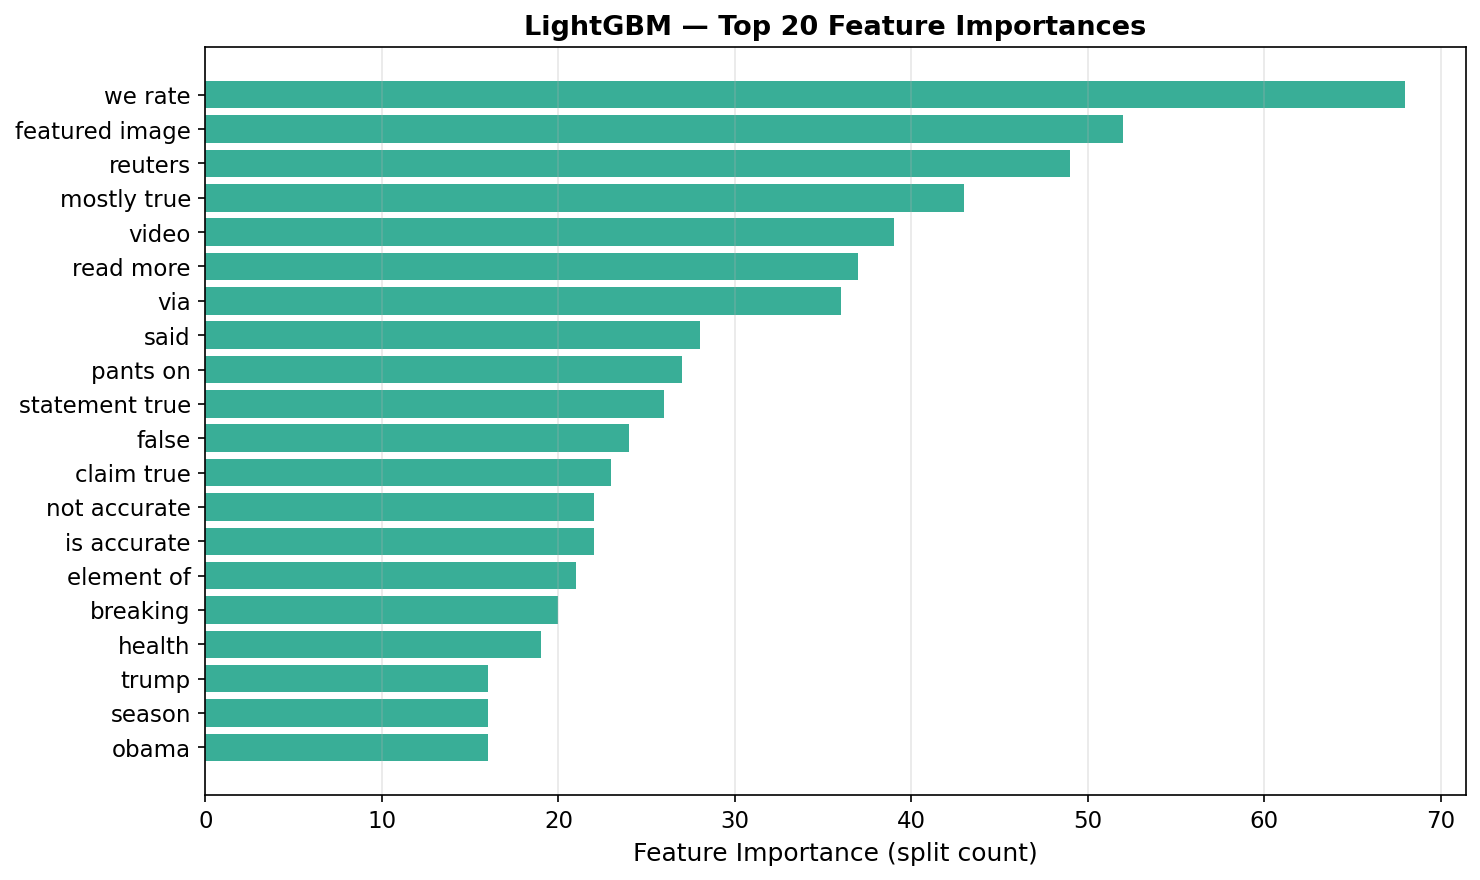

In [9]:
feat_names = np.array(tfidf.get_feature_names_out())
fi = model.feature_importances_
top_idx = np.argsort(fi)[-20:][::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(feat_names[top_idx][::-1], fi[top_idx[::-1]], color='#16a085', alpha=0.85)
ax.set_xlabel('Feature Importance (split count)')
ax.set_title('LightGBM — Top 20 Feature Importances')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'lightgbm_feature_importance.png'), dpi=150, bbox_inches='tight')
plt.show()

## Learning Curve

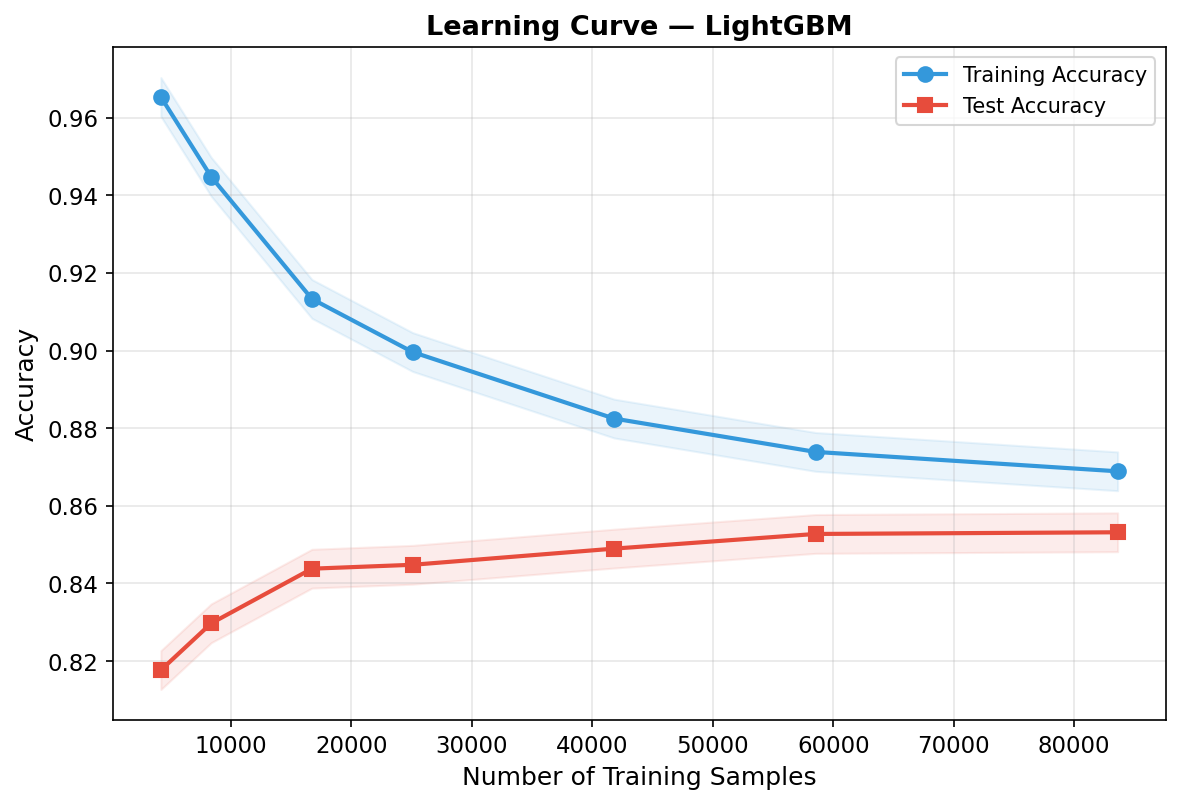

([4180, 8361, 16723, 25084, 41808, 58531, 83616],
 [0.965311004784689,
  0.9447434517402225,
  0.9132930694253424,
  0.8996172859193111,
  0.8824866054343666,
  0.8738958842322871,
  0.8689006888633755],
 [0.8176991150442477,
  0.8297536474527625,
  0.8438172685960297,
  0.8448218129634059,
  0.8489834967711074,
  0.8527624970102846,
  0.8531930160248744])

In [10]:
plot_learning_curve(model, X_tr, y_train, X_te, y_test, MODEL_NAME, FIGURES_DIR)